# Patch Embedding

Reimplementation of the patch embedding step from [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929) (Dosovitskiy et al., 2020), using only basic PyTorch layers.

![Patch Embeddings](../assets/patch_embedding.gif)

In this notebook I implement image patching and the linear projection $\mathbf{x}^i_p\mathbf{E}$ from Eq. 1, the first part of the layer that produces the embedded patches used by the later Vision Transformer layers.

**Contents**
1. Setup
2. Data
3. Patchifying images
4. Patch embedding module

## 1. Setup

In [1]:
import os
import random
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

In [2]:
DATA_PATH = Path("../data/")
RAW_IMAGES_PATH = DATA_PATH / "raw"

IMAGE_SIZE = 256  # H = W
PATCH_SIZE = 16  # P
COLOR_CHANNELS = 3  # C
EMBED_DIM = 768  # D

assert IMAGE_SIZE % PATCH_SIZE == 0, "Image size must be divisible by patch size"
NUM_OF_PATCHES = (IMAGE_SIZE // PATCH_SIZE) ** 2  # N

## 2. Data

In [3]:
def set_seed(seed: int = 42):
    """Seeds PyTorch's CPU and CUDA random number generators for reproducible runs.

    Args:
        seed: Seed value passed to the generators.
    """
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

In [4]:
def walk_through_dir(dir_path: str):
    """
    Walks through dir_path returning its contents.
    Args:
        dir_path (str or pathlib.Path): target directory
    
    Returns:
        A print out of:
        number of subdiretories in dir_path
        number of images (files) in each subdirectory
        name of each subdirectory
    """
    for dirpath, _, filenames in os.walk(dir_path):
        if dirpath == str(dir_path):
            continue
        print(f"There are and {len(filenames)} images in '{dirpath}'.")

In [5]:
CLASSES = os.listdir(RAW_IMAGES_PATH)

walk_through_dir(RAW_IMAGES_PATH)

There are and 100 images in '../data/raw/forest'.
There are and 100 images in '../data/raw/buildings'.
There are and 100 images in '../data/raw/river'.
There are and 100 images in '../data/raw/mobilehomepark'.
There are and 100 images in '../data/raw/harbor'.
There are and 100 images in '../data/raw/golfcourse'.
There are and 100 images in '../data/raw/agricultural'.
There are and 100 images in '../data/raw/runway'.
There are and 100 images in '../data/raw/baseballdiamond'.
There are and 100 images in '../data/raw/overpass'.
There are and 100 images in '../data/raw/chaparral'.
There are and 100 images in '../data/raw/tenniscourt'.
There are and 100 images in '../data/raw/intersection'.
There are and 100 images in '../data/raw/airplane'.
There are and 100 images in '../data/raw/parkinglot'.
There are and 100 images in '../data/raw/sparseresidential'.
There are and 100 images in '../data/raw/mediumresidential'.
There are and 100 images in '../data/raw/denseresidential'.
There are and 100

In [6]:
image_paths = []

for dirpath, dirnames, filenames in os.walk(RAW_IMAGES_PATH):
    for filename in filenames:
        if filename == ".DS_Store":
            continue
        image_paths.append(Path(dirpath) / filename)

print(f"There are {len(image_paths)} images in total.")

There are 2100 images in total.


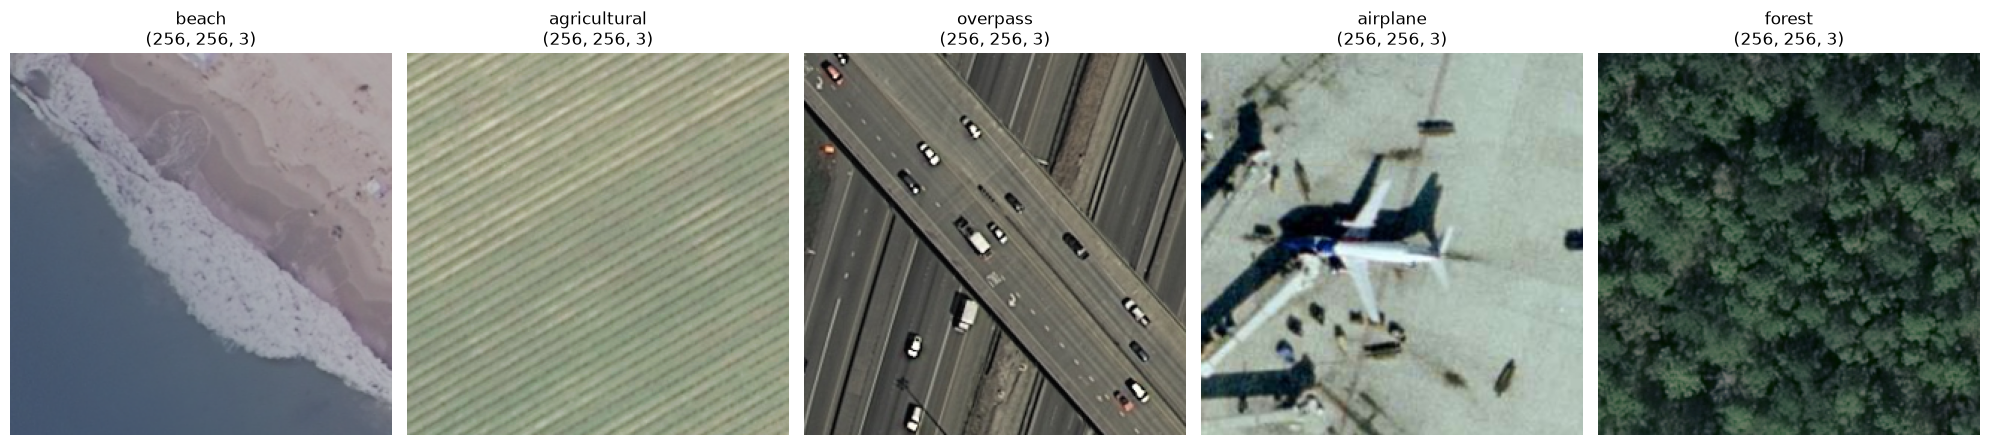

In [7]:
random_image_paths = random.sample(image_paths, k=5)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, image_path in zip(axes, random_image_paths):
    image = cv.cvtColor(cv.imread(str(image_path)), cv.COLOR_BGR2RGB)
    ax.imshow(image)
    ax.set_title(f"{image_path.parent.name}\n{image.shape}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Patchifying images

An image of shape $(H, W, C)$ is cut into $N = HW / P^2$ non-overlapping $P \times P$ patches. Each patch is flattened into a vector of $P^2 \cdot C$ values, giving a matrix of shape $(N, P^2 \cdot C)$.

In [8]:
embedding_layer_input_shape = (IMAGE_SIZE, IMAGE_SIZE, COLOR_CHANNELS)
embedding_layer_output_shape = (NUM_OF_PATCHES, PATCH_SIZE**2 * COLOR_CHANNELS)

print(f"Number of patches (N) with image height (H={IMAGE_SIZE}), width (W={IMAGE_SIZE}) and patch size (P={PATCH_SIZE}): {NUM_OF_PATCHES}")
print(f"Input shape (single 2D image): {embedding_layer_input_shape}")
print(f"Output shape (single 2D image flattened into patches): {embedding_layer_output_shape}")

Number of patches (N) with image height (H=256), width (W=256) and patch size (P=16): 256
Input shape (single 2D image): (256, 256, 3)
Output shape (single 2D image flattened into patches): (256, 768)


### 3.1 Visualizing patches

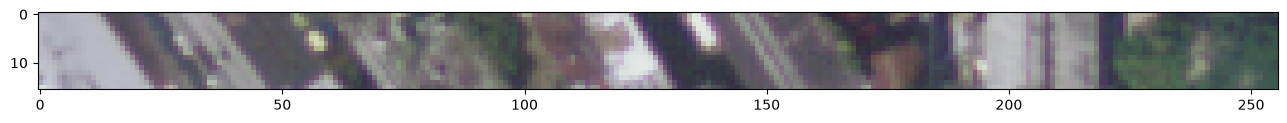

In [9]:
image = cv.cvtColor(cv.imread(str(image_paths[351])), cv.COLOR_BGR2RGB)

plt.figure(figsize=(PATCH_SIZE, PATCH_SIZE))
plt.imshow(image[:PATCH_SIZE, :, :])

Number of patches per row: 16
Patch size: 16 pixels x 16 pixels


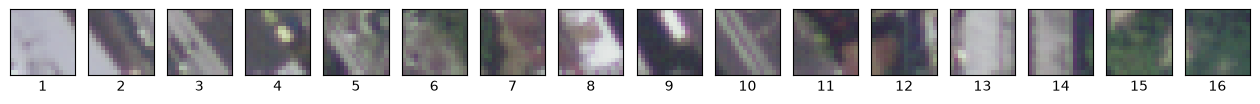

In [10]:
patches_per_row = IMAGE_SIZE // PATCH_SIZE
print(f"Number of patches per row: {patches_per_row}\nPatch size: {PATCH_SIZE} pixels x {PATCH_SIZE} pixels")

fig, axs = plt.subplots(
    nrows=1,
    ncols=patches_per_row,
    figsize=(patches_per_row, patches_per_row),
    sharex=True,
    sharey=True,
)

for idx, patch in enumerate(range(0, IMAGE_SIZE, PATCH_SIZE)):
    axs[idx].imshow(image[:PATCH_SIZE, patch:patch+PATCH_SIZE, :])
    axs[idx].set_xlabel(idx+1)
    axs[idx].set_xticks([])
    axs[idx].set_yticks([])

Number of patches per row: 16    
Number of patches per column: 16    
Total patches: 256    
Patch size: 16 pixels x 16 pixels


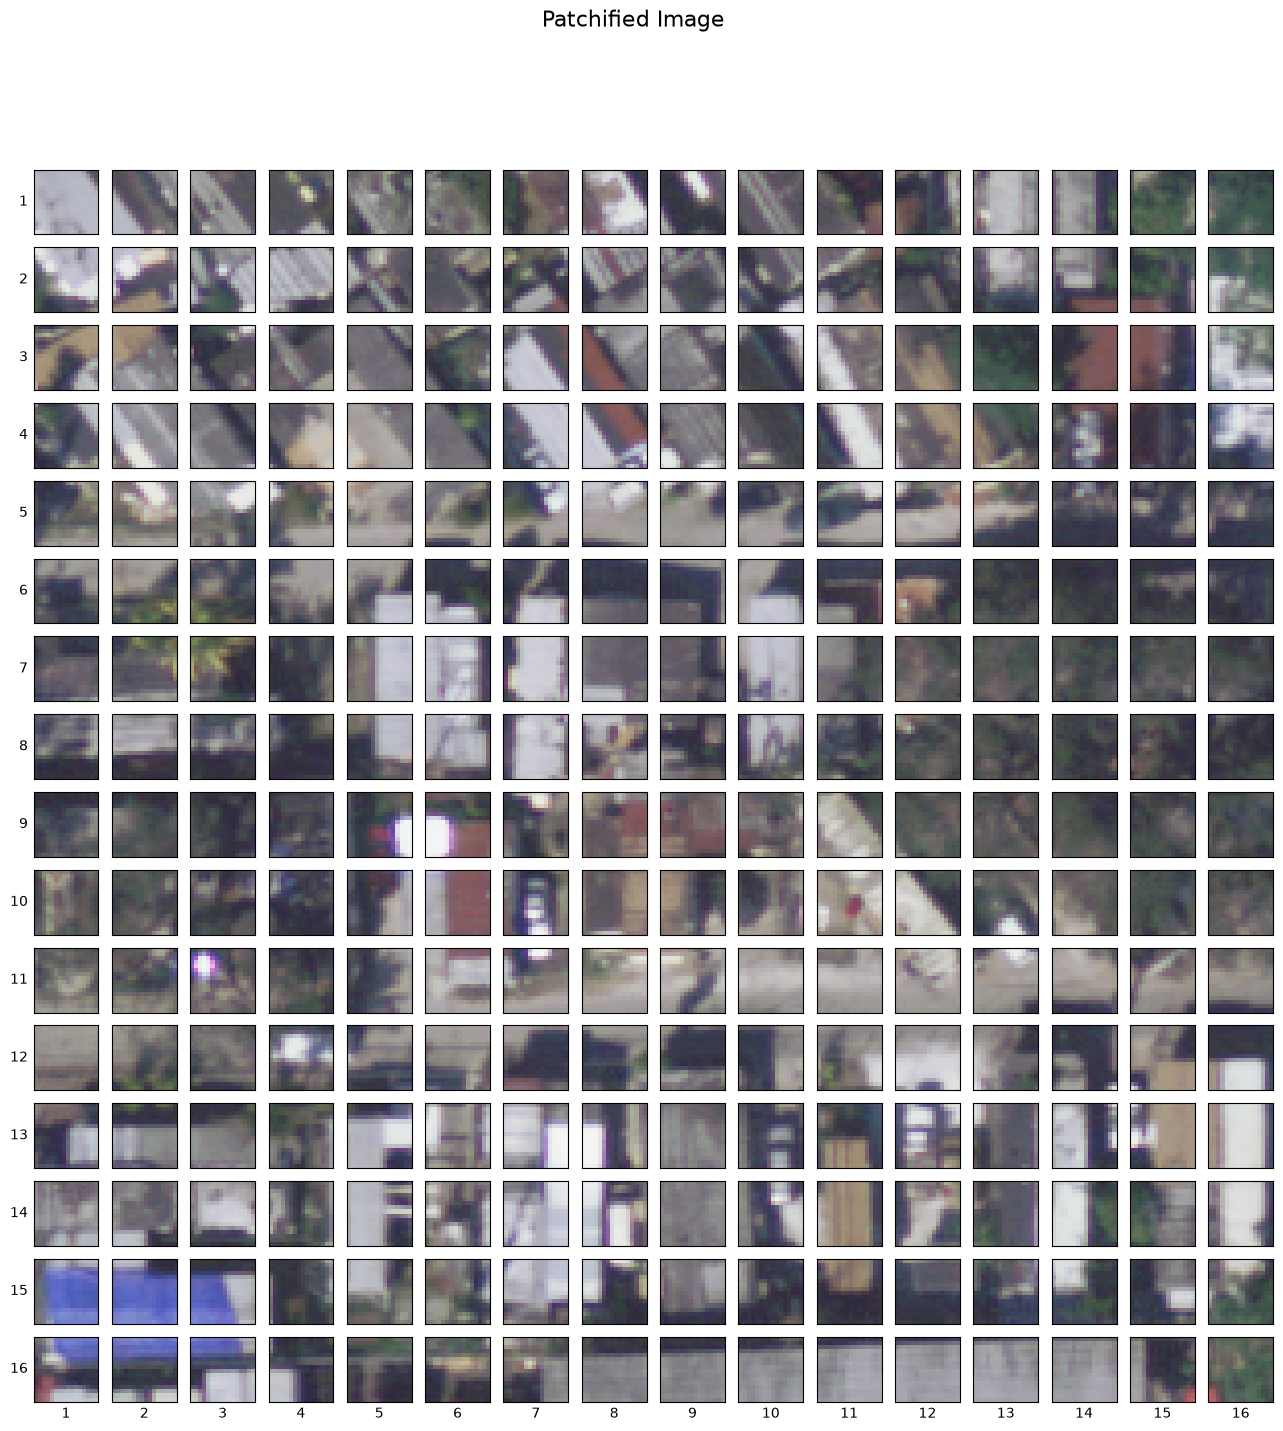

In [11]:
print(
    f"Number of patches per row: {patches_per_row}\
    \nNumber of patches per column: {patches_per_row}\
    \nTotal patches: {NUM_OF_PATCHES}\
    \nPatch size: {PATCH_SIZE} pixels x {PATCH_SIZE} pixels"
)

fig, axs = plt.subplots(
    nrows=patches_per_row,
    ncols=patches_per_row,
    figsize=(patches_per_row, patches_per_row),
    sharex=True,
    sharey=True,
)

for i, patch_height in enumerate(range(0, IMAGE_SIZE, PATCH_SIZE)):
    for j, patch_width in enumerate(range(0, IMAGE_SIZE, PATCH_SIZE)):
        axs[i, j].imshow(image[
            patch_height:patch_height+PATCH_SIZE,
            patch_width:patch_width+PATCH_SIZE,
            :
        ])

        axs[i, j].set_ylabel(
            i+1,
            rotation="horizontal",
            horizontalalignment="right",
            verticalalignment="center"
        )
        axs[i, j].set_xlabel(j+1)
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])
        axs[i, j].label_outer()

fig.suptitle("Patchified Image", fontsize=16)
plt.show()

### 3.2 `patchify` function

In [12]:
def patchify(image: np.ndarray, patch_size: int) -> np.ndarray:
    """Splits an image into flattened non-overlapping patches.

    Args:
        image: Array of shape (H, W, C).
        patch_size: Side length P of each square patch.

    Returns:
        Array of shape (N, P*P*C) where N = (H // P) * (W // P).
    """
    height, width, _ = image.shape
    assert height % patch_size == 0 and width % patch_size == 0, (
        f"image size {height}x{width} not divisible by patch_size={patch_size}"
    )

    patches = []
    for patch_height in range(0, height, patch_size):
        for patch_width in range(0, width, patch_size):
            patches.append(image[
                patch_height:patch_height+patch_size,
                patch_width:patch_width+patch_size,
                :
            ].reshape(-1))

    return np.array(patches)

In [13]:
image = cv.cvtColor(cv.imread(str(image_paths[0])), cv.COLOR_BGR2RGB)

patches = patchify(image, PATCH_SIZE)
patches.shape

(256, 768)

In [14]:
# nn.Linear needs float input; scaling uint8 [0, 255] to [0, 1] keeps activations in a sane range
patches_tensor = torch.from_numpy(patches).float() / 255.0

patches_tensor.shape, patches_tensor.dtype

(torch.Size([256, 768]), torch.float32)

## 4. Patch embedding module

Each flattened patch $\mathbf{x}^i_p$ is mapped to $D$ dimensions by the trainable linear projection $\mathbf{E} \in \mathbb{R}^{(P^2 \cdot C) \times D}$, applied to every patch with shared weights. `in_features` is fixed by how the image is cut, `out_features` is the model width $D$.

In [15]:
class PatchEmbedding(nn.Module):
    """Patchifies a batch of images, projects each patch to embed_dim dimensions and prepends a class token.

    Args:
        patch_size: Side length P of each square patch.
        color_channels: Number of image channels C.
        embed_dim: Embedding dimension D.
    """

    def __init__(self, patch_size: int, color_channels: int, embed_dim: int):
        super().__init__()
        self.patch_size = patch_size
        self.linear = nn.Linear(in_features=patch_size * patch_size * color_channels, out_features=embed_dim)

        self.class_token = torch.nn.Parameter(torch.ones((1, 1, embed_dim), requires_grad=True))
        self.position_embedding = torch.nn.Parameter(torch.ones((1, NUM_OF_PATCHES+1, embed_dim), requires_grad=True))


    def patchify(self, images: torch.Tensor) -> torch.Tensor:
        """Splits a batch of images into flattened non-overlapping patches without looping.

        Args:
            images: Tensor of shape (B, C, H, W).

        Returns:
            Tensor of shape (B, N, P*P*C), same patch and pixel order as the loop-based patchify.
        """
        batch_size, color_channels, height, width = images.shape
        assert height % self.patch_size == 0 and width % self.patch_size == 0, (
            f"image size {height}x{width} not divisible by patch_size={self.patch_size}"
        )
        p = self.patch_size

        # Split H into (patch_row, row_inside_patch) and W into (patch_col, col_inside_patch)
        patches = images.reshape(batch_size, color_channels, height // p, p, width // p, p)
        # (B, C, patch_row, r, patch_col, c) -> (B, patch_row, patch_col, r, c, C) so each patch is one block,
        # with channels last inside a patch to keep the loop-based pixel order
        patches = patches.permute(0, 2, 4, 3, 5, 1)
        return patches.reshape(batch_size, -1, p * p * color_channels)

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        """Computes the patch embeddings of a batch of images.

        Args:
            images: Float tensor of shape (B, C, H, W).

        Returns:
            Tensor of shape (B, N+1, D), with the class token at position 0.
        """
        patch_embeddings = self.linear(self.patchify(images))

        class_token = self.class_token.expand(images.shape[0], -1, -1)
        return torch.cat([class_token, patch_embeddings], dim=1) + self.position_embedding

In [16]:
set_seed()

image = cv.cvtColor(cv.imread(str(image_paths[551])), cv.COLOR_BGR2RGB)
print(f"Image tensor shape: {image.shape}")

height, width = image.shape[0], image.shape[1]

x = (torch.from_numpy(image).float() / 255.0).permute(2, 0, 1).unsqueeze(0)
print(f"Input image with batch dimension shape: {x.shape}")

patch_embedding_layer = PatchEmbedding(PATCH_SIZE, COLOR_CHANNELS, EMBED_DIM)

patch_and_position_embedding = patch_embedding_layer(x)
print(f"Patch and position embedding shape: {patch_and_position_embedding.shape}")

Image tensor shape: (256, 256, 3)
Input image with batch dimension shape: torch.Size([1, 3, 256, 256])
Patch and position embedding shape: torch.Size([1, 257, 768])
